# Quantflux — Historical Market Data Exploration

This notebook explores historical financial market data using the Quantflux Python library.

The analysis includes:

- Historical stock prices
- Daily simple, gross, and logarithmic returns
- Cumulative growth and returns
- Rolling annualized volatility
- Running price peaks and drawdowns
- Numerical verification and visualization

We use historical market data from Yahoo Finance, retrieved through the `yfinance` library.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the root of the Quantflux project
project_root = Path.cwd().parent

# Allow JupyterLab to import our local Python modules
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import the functions developed in VS Code
from src.data.yfinance_provider import load_stock_data, add_market_features
from src.data.validation import validate_market_data
from src.visualization.market_plots import plot_prices, plot_cumulative_returns, plot_rolling_volatility, plot_drawdowns
print("Quantflux modules imported successfully!")

Quantflux modules imported successfully!


## 1. Historical Market Data

We retrieve daily historical market data for three financial instruments:

- **AAPL** — Apple Inc.
- **MSFT** — Microsoft Corporation
- **SPY** — SPDR S&P 500 ETF Trust

The data is downloaded through our `load_stock_data()` function.

The dataset includes adjusted closing prices, closing prices, opening prices, daily highs and lows, and trading volumes.

Before returning the dataset, our function validates the data to ensure that the adjusted closing prices are valid and the observations are chronologically ordered.

In [2]:
# Define the financial instruments
tickers = ["AAPL", "MSFT", "SPY"]

# Define the historical analysis period
start_date="2024-01-01"
end_date="2025-01-01"

# Retrieve and validate historical market data
data = load_stock_data(tickers,start=start_date,end=end_date)

# Inspect the first five observations
data.head()

Price        Adj Close                               Close              \
Ticker            AAPL        MSFT         SPY        AAPL        MSFT   
Date                                                                     
2024-01-02  183.404007  363.117889  457.672699  185.639999  370.869995   
2024-01-03  182.030746  362.853577  453.934998  184.250000  370.600006   
2024-01-04  179.718933  360.249237  452.472900  181.910004  367.940002   
2024-01-05  178.997726  360.063171  453.092621  181.179993  367.750000   
2024-01-08  183.324982  366.858124  459.560944  185.559998  374.690002   

Price                         High                                 Low  \
Ticker             SPY        AAPL        MSFT         SPY        AAPL   
Date                                                                     
2024-01-02  472.649994  188.440002  375.899994  473.670013  183.889999   
2024-01-03  468.790009  185.880005  373.260010  471.190002  183.429993   
2024-01-04  467.279999  183.089996  373.100006  470.959991  180.880005   
2024-01-05  467.920013  182.759995  372.059998  470.440002  180.169998   
2024-01-08  474.600006  185.600006  375.200012  474.750000  181.500000   

Price                                     Open                          \
Ticker            MSFT         SPY        AAPL        MSFT         SPY   
Date                                                                     
2024-01-02  366.769989  470.489990  187.149994  373.859985  472.160004   
2024-01-03  368.510010  468.170013  184.220001  369.010010  470.429993   
2024-01-04  367.170013  467.049988  182.149994  370.670013  468.299988   
2024-01-05  366.500000  466.429993  181.990005  368.970001  467.489990   
2024-01-08  369.010010  468.299988  182.089996  369.299988  468.429993   

Price         Volume                       
Ticker          AAPL      MSFT        SPY  
Date                                       
2024-01-02  82488700  25258600  123623700  
2024-01-03  58414500  23083500  103585900  
2024-01-04  71983600  20901500   84232200  
2024-01-05  62379700  21004600   86118900  
2024-01-08  59144500  23134000   74879100

## 2. Market Data Structure

The historical data is stored in a Pandas DataFrame with a two-level column index, known as a MultiIndex.

- **Level 0:** Financial variables such as Adj Close, Close, and Volume.
- **Level 1:** Stock ticker symbols such as AAPL, MSFT, and SPY.

This structure allows us to select one financial variable across multiple stocks and apply calculations to all of them simultaneously.

In [3]:
# Examine the dimensions of the dataset
print("Dataset shape:", data.shape)

# Examine the column structure
print("\nColumn levels:")
print(data.columns.names)

# List the available financial variables
print("\nAvailable variables:")
print(data.columns.get_level_values(0).unique().tolist())

# Extract adjusted closing prices for all tickers
prices = data["Adj Close"]

# Display the first five observations
prices.head()

Dataset shape: (252, 18)

Column levels:
['Price', 'Ticker']

Available variables:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


Ticker,AAPL,MSFT,SPY
Date,,,
2024-01-02,183.404007,363.117889,457.672699
2024-01-03,182.030746,362.853577,453.934998
2024-01-04,179.718933,360.249237,452.472900
2024-01-05,178.997726,360.063171,453.092621
2024-01-08,183.324982,366.858124,459.560944


## 3. Financial Market Features

We use the `add_market_features()` function to calculate financial variables from historical adjusted closing prices.

The function calculates:

- **Simple Return:** Daily percentage change in price.
- **Gross Return:** Daily growth factor.
- **Log Return:** Continuously compounded daily return.
- **Rolling Volatility:** Annualized standard deviation of daily log returns.
- **Cumulative Growth:** Growth of an initial $1 investment.
- **Cumulative Return:** Total percentage return since the initial date.
- **Running Peak:** Highest adjusted closing price observed so far.
- **Drawdown:** Percentage decline relative to the previous peak.

The calculations are applied independently to all three financial instruments while preserving the DataFrame's MultiIndex structure.

In [4]:
# Calculate all financial variables
market_data = add_market_features(data,volatility_window=21)

# Check the resulting DataFrame dimensions
print("Original shape:", data.shape)
print("Updated shape:", market_data.shape)

# List the financial variables available
print("\nAvailable variables:")
print(market_data.columns.get_level_values(0).unique().tolist())

# Display the first five observations
market_data.head()

Original shape: (252, 18)
Updated shape: (252, 42)

Available variables:
['Adj Close', 'Close', 'Cumulative Growth', 'Cumulative Return', 'Drawdown', 'Gross Return', 'High', 'Log Return', 'Low', 'Open', 'Return', 'Rolling Volatility', 'Running Peak', 'Volume']


Adj Close                               Close              \
Ticker            AAPL        MSFT         SPY        AAPL        MSFT   
Date                                                                     
2024-01-02  183.404007  363.117889  457.672699  185.639999  370.869995   
2024-01-03  182.030746  362.853577  453.934998  184.250000  370.600006   
2024-01-04  179.718933  360.249237  452.472900  181.910004  367.940002   
2024-01-05  178.997726  360.063171  453.092621  181.179993  367.750000   
2024-01-08  183.324982  366.858124  459.560944  185.559998  374.690002   

                       Cumulative Growth                      \
Ticker             SPY              AAPL      MSFT       SPY   
Date                                                           
2024-01-02  472.649994          1.000000  1.000000  1.000000   
2024-01-03  468.790009          0.992512  0.999272  0.991833   
2024-01-04  467.279999          0.979907  0.992100  0.988639   
2024-01-05  467.920013          0.975975  0.991588  0.989993   
2024-01-08  474.600006          0.999569  1.010300  1.004126   

           Cumulative Return  ...    Return Rolling Volatility           \
Ticker                  AAPL  ...       SPY               AAPL MSFT SPY   
Date                          ...                                         
2024-01-02          0.000000  ...       NaN                NaN  NaN NaN   
2024-01-03         -0.007488  ... -0.008167                NaN  NaN NaN   
2024-01-04         -0.020093  ... -0.003221                NaN  NaN NaN   
2024-01-05         -0.024025  ...  0.001370                NaN  NaN NaN   
2024-01-08         -0.000431  ...  0.014276                NaN  NaN NaN   

           Running Peak                            Volume                       
Ticker             AAPL        MSFT         SPY      AAPL      MSFT        SPY  
Date                                                                            
2024-01-02   183.404007  363.117889  457.672699  82488700  25258600  123623700  
2024-01-03   183.404007  363.117889  457.672699  58414500  23083500  103585900  
2024-01-04   183.404007  363.117889  457.672699  71983600  20901500   84232200  
2024-01-05   183.404007  363.117889  457.672699  62379700  21004600   86118900  
2024-01-08   183.404007  366.858124  459.560944  59144500  23134000   74879100  

[5 rows x 42 columns]

In [5]:
# Display daily simple, gross, and log returns
market_data[["Return", "Gross Return", "Log Return"]].head(10)

Return                     Gross Return                      \
Ticker          AAPL      MSFT       SPY         AAPL      MSFT       SPY   
Date                                                                        
2024-01-02       NaN       NaN       NaN          NaN       NaN       NaN   
2024-01-03 -0.007488 -0.000728 -0.008167     0.992512  0.999272  0.991833   
2024-01-04 -0.012700 -0.007177 -0.003221     0.987300  0.992823  0.996779   
2024-01-05 -0.004013 -0.000516  0.001370     0.995987  0.999484  1.001370   
2024-01-08  0.024175  0.018872  0.014276     1.024175  1.018872  1.014276   
2024-01-09 -0.002263  0.002936 -0.001517     0.997737  1.002936  0.998483   
2024-01-10  0.005671  0.018574  0.005655     1.005671  1.018574  1.005655   
2024-01-11 -0.003223  0.004860 -0.000441     0.996777  1.004860  0.999559   
2024-01-12  0.001778  0.009984  0.000693     1.001778  1.009984  1.000693   
2024-01-16 -0.012317  0.004633 -0.003671     0.987683  1.004633  0.996329   

           Log Return                      
Ticker           AAPL      MSFT       SPY  
Date                                       
2024-01-02        NaN       NaN       NaN  
2024-01-03  -0.007516 -0.000728 -0.008200  
2024-01-04  -0.012781 -0.007203 -0.003226  
2024-01-05  -0.004021 -0.000517  0.001369  
2024-01-08   0.023887  0.018696  0.014175  
2024-01-09  -0.002266  0.002931 -0.001518  
2024-01-10   0.005655  0.018404  0.005639  
2024-01-11  -0.003228  0.004848 -0.000441  
2024-01-12   0.001777  0.009934  0.000693  
2024-01-16  -0.012394  0.004623 -0.003678

## 4. Numerical Verification

We verify the financial calculations by comparing the software's outputs against values calculated directly from historical prices.

For two consecutive adjusted closing prices, the daily simple return is

$$
R_t = \frac{P_t}{P_{t-1}} - 1
$$

The gross return is

$$
G_t = \frac{P_t}{P_{t-1}} = 1 + R_t
$$

The logarithmic return is

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

These variables satisfy the mathematical identity

$$
G_t = 1 + R_t = e^{r_t}
$$

We independently calculate these quantities for one historical observation and compare them with the results from Quantflux.

In [6]:
import math

# Select Microsoft for our numerical verification
ticker = "MSFT"

# Select two consecutive adjusted closing prices
p0=float(data["Adj Close"][ticker].iloc[0])
p1=float(data["Adj Close"][ticker].iloc[1])

# Independently calculate the three financial variables
manual_return = p1/p0 -1
manual_gross = p1/p0
manual_log = math.log(p1/p0)

# Retrive the results calculated by Quantflux
software_return = market_data["Return"][ticker].iloc[1]
software_gross = market_data["Gross Return"][ticker].iloc[1]
software_log = market_data["Log Return"][ticker].iloc[1]

# Compare the independently calculated values
checks = {
    "Simple Return": math.isclose(manual_return, software_return, rel_tol=1e-10),
    "Gross Return": math.isclose(manual_gross, software_gross, rel_tol=1e-10),
    "Log Return": math.isclose(manual_log, software_log, rel_tol=1e-10)
}

# Display verification results
verification=pd.DataFrame({
    "Manual": [manual_return, manual_gross, manual_log],
    "Quantflux": [software_return, software_gross, software_log],
    "Verified": list(checks.values())
}, index=list(checks.keys()))

verification

,Manual,Quantflux,Verified
Simple Return,-0.000728,-0.000728,True
Gross Return,0.999272,0.999272,True
Log Return,-0.000728,-0.000728,True


In [7]:
# Stop execution if any calculation fails verification
assert verification["Verified"].all()
print("All selected financial returns verified successfully!")

All selected financial returns verified successfully!


## 5. Financial Market Visualization

We visualize historical financial variables to study market behavior and compare different financial instruments.

### 5.1 Adjusted Closing Prices

Adjusted closing prices account for stock splits and dividend adjustments, making them useful for historical return analysis.

We begin by plotting the adjusted closing prices of AAPL, MSFT, and SPY over the selected period.

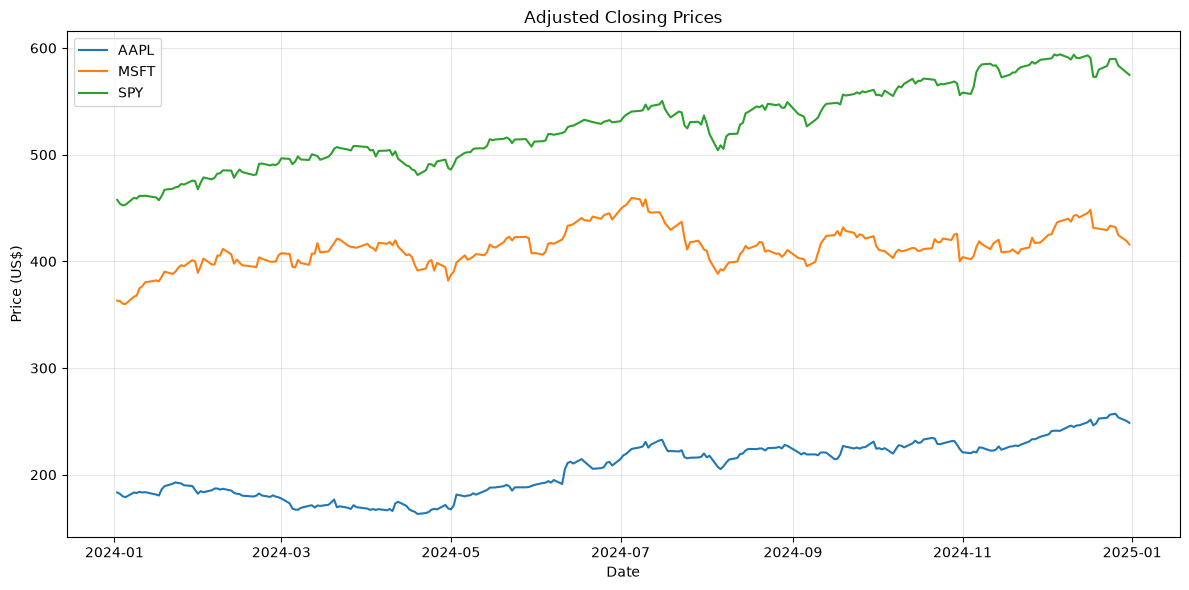

In [8]:
fig, ax = plot_prices(market_data)

### 5.2 Cumulative Returns

Cumulative returns measure the total percentage change in an investment relative to its initial value.

For an adjusted closing price $P_t$ at time $t$ and an initial price $P_0$, the cumulative return is

$$
C_t = \frac{P_t}{P_0} - 1
$$

At the beginning of the observation period, $C_0 = 0$.

Unlike absolute stock prices, cumulative returns allow us to compare the historical performance of different financial instruments on the same percentage scale.

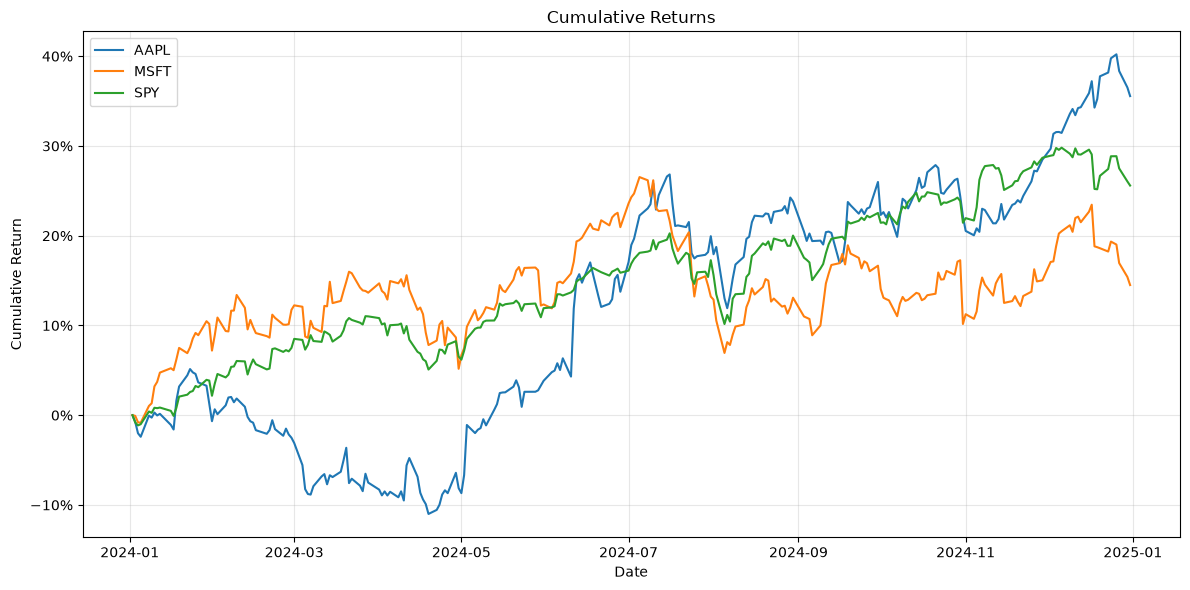

In [9]:
fig, ax = plot_cumulative_returns(market_data)

### 5.3 Rolling Annualized Volatility

Rolling volatility measures the variability of daily returns over a moving window of observations.

We calculate volatility using daily logarithmic returns:

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

For a window containing $w$ returns, the sample standard deviation is

$$
s_t = \sqrt{
\frac{1}{w-1}
\sum_{i=t-w+1}^{t}(r_i-\bar{r}_t)^2
}
$$

where $\bar{r}_t$ is the mean logarithmic return within the window.

We annualize this quantity using

$$
\sigma_t = s_t\sqrt{252}
$$

where 252 approximates the number of trading days in a year.

We use a rolling window of 21 trading days, approximately one trading month.

This allows us to study how historical volatility changes over time and compare fluctuations across financial instruments. Annualization assumes the usual square-root-of-time scaling and does not make the estimate a forecast of future volatility.

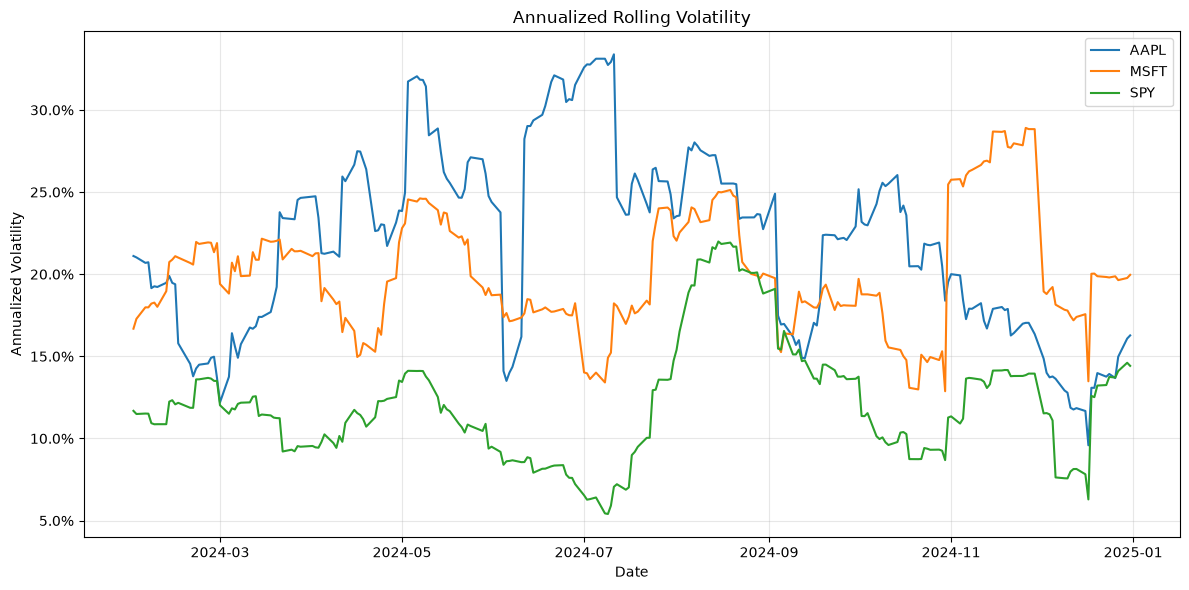

In [10]:
fig, ax = plot_rolling_volatility(market_data)

In [11]:
# Summary statistics for rolling annualized volatility
rolling_volatility = market_data["Rolling Volatility"]
rolling_volatility.describe()

Ticker,AAPL,MSFT,SPY
count,231.000000,231.000000,231.000000
mean,0.218858,0.200088,0.121035
std,0.055785,0.036074,0.035422
min,0.095846,0.128754,0.054041
25%,0.170387,0.176929,0.094987
50%,0.226708,0.193652,0.115640
75%,0.256060,0.221162,0.137536
max,0.333867,0.289070,0.219917


### 5.4 Historical Drawdowns

A drawdown measures the percentage decline in an asset's price relative to its highest previously observed price.

First, we define the running peak as

$$
P_t^{\max} = \max_{0 \leq i \leq t} P_i
$$

where $P_i$ is the adjusted closing price at time $i$.

The drawdown is then defined as

$$
D_t = \frac{P_t}{P_t^{\max}} - 1
$$

Drawdowns are zero when the price reaches a new historical peak and negative when the price falls below that peak.

The maximum drawdown over an observation period is

$$
D_{\min} = \min_t D_t
$$

This represents the largest percentage decline from a previous peak during the selected period.

Unlike volatility, which measures return fluctuations, drawdowns describe the magnitude of historical losses relative to previous price peaks.

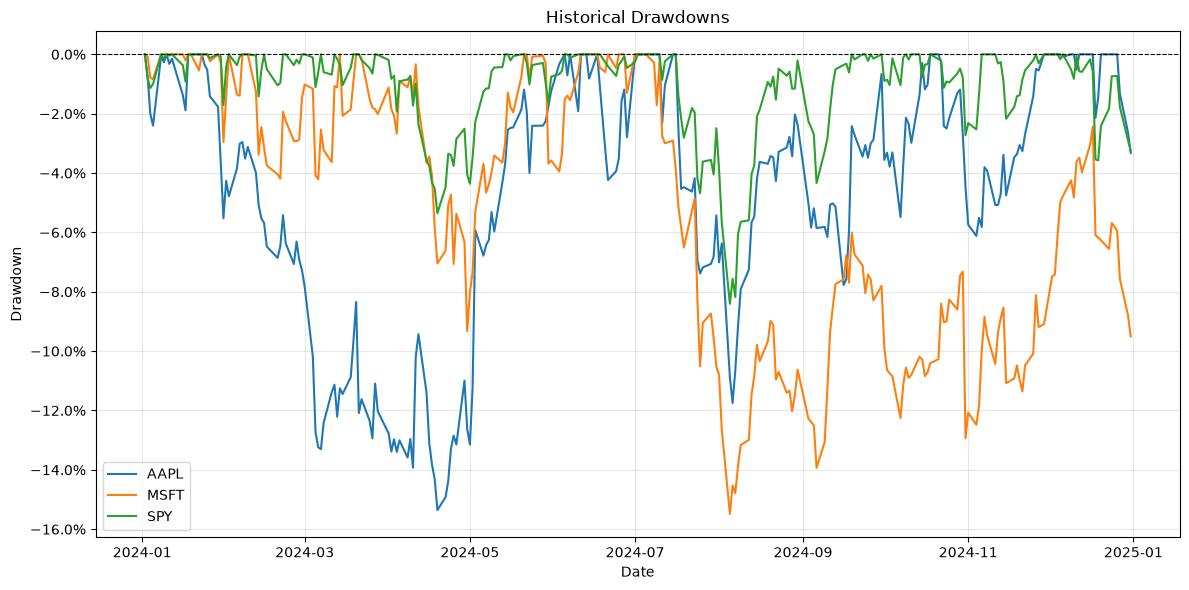

In [12]:
fig, ax = plot_drawdowns(market_data)

In [13]:
# Find the largest historical decline for each ticker
drawdowns = market_data["Drawdown"]
maximum_drawdowns = drawdowns.min()

# Display maximum drawdowns as percentages
print("Maximum historical drawdowns:")
print(maximum_drawdowns.map(lambda x: f"{x:.2%}"))

Maximum historical drawdowns:
Ticker
AAPL    -15.35%
MSFT    -15.49%
SPY      -8.41%
dtype: str


## 6. Final Consistency Checks

We perform several mathematical consistency checks across the historical dataset.

The gross, simple, and logarithmic returns must satisfy

$$
G_t = 1 + R_t = e^{r_t}
$$

Cumulative growth and cumulative return must satisfy

$$
C_t = G_t^{\mathrm{cum}} - 1
$$

At the initial observation, cumulative growth must equal 1 and cumulative return must equal 0.

We also verify that rolling volatility is nonnegative and drawdowns are nonpositive.

These checks complement the automated unit tests by verifying relationships across the downloaded historical dataset.

In [14]:
# Extract the calculated financial variables
returns = market_data["Return"]
gross_returns = market_data["Gross Return"]
log_returns = market_data["Log Return"]

cumulative_growth = market_data["Cumulative Growth"]
cumulative_returns = market_data["Cumulative Return"]

# Check mathematical relationships and initial conditions
checks = {
    "Gross Return = 1 + Simple Return": np.allclose(gross_returns, 1 + returns, equal_nan=True),
    "Gross Return = exp(Log Return)": np.allclose(gross_returns, np.exp(log_returns), equal_nan=True),
    "Cumulative Return = Cumulative Growth - 1": np.allclose(cumulative_returns, cumulative_growth - 1, equal_nan=True),
    "Initial Cumulative Growth = 1": np.allclose(cumulative_growth.iloc[0], 1),
    "Initial Cumulative Return = 0": np.allclose(cumulative_returns.iloc[0], 0),
    "Rolling Volatility >= 0": (rolling_volatility.dropna() >= 0).all().all(),
    "Drawdown <= 0": (drawdowns.dropna() <= 0).all().all(),
}

# Display verification results
final_checks = pd.Series(checks, name="Passed")
final_checks

Gross Return = 1 + Simple Return             True
Gross Return = exp(Log Return)               True
Cumulative Return = Cumulative Growth - 1    True
Initial Cumulative Growth = 1                True
Initial Cumulative Return = 0                True
Rolling Volatility >= 0                      True
Drawdown <= 0                                True
Name: Passed, dtype: bool